## Лабораторная работа №1 | Вариант 6

Выполнил: Богданов Михаил

### 1. Numpy

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [2]:
a1 = np.eye(3)
print(a1)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [3]:
a2 = np.diag([1, 2, 3, 4], -1)
print(a2)

[[0 0 0 0 0]
 [1 0 0 0 0]
 [0 2 0 0 0]
 [0 0 3 0 0]
 [0 0 0 4 0]]


3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

In [4]:
print(sum(range(5), -1))
from numpy import *
print(sum(range(5), -1))

9
10


4. Как найти самое часто встречаемое значение между двумя массивами? 

In [5]:
a = np.array([1, 2, 3, 2, 4, 2])
b = np.array([2, 3, 3, 5])
vals, counts = np.unique(np.concatenate([a, b]), return_counts=True)
print("Самое частое значение:", vals[counts.argmax()])

Самое частое значение: 2


5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

In [6]:
import warnings
warnings.simplefilter("ignore")
x = np.array([1, 2, 3]) / np.array([0, 1, 0])
print(x)

[inf  2. inf]


6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [7]:
def gen10():
    for i in range(10):
        yield i * 3

a6 = np.array(list(gen10()))
print(a6)

[ 0  3  6  9 12 15 18 21 24 27]


7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [8]:
a7 = np.random.rand(10)
print(a7)
print(np.sort(a7))

[0.41037351 0.85079277 0.70115809 0.88044187 0.18932238 0.08122003
 0.3514197  0.16280402 0.94050408 0.45009728]
[0.08122003 0.16280402 0.18932238 0.3514197  0.41037351 0.45009728
 0.70115809 0.85079277 0.88044187 0.94050408]


8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [9]:
xy = np.random.rand(10, 2)
r = np.hypot(xy[:, 0], xy[:, 1])
theta = np.arctan2(xy[:, 1], xy[:, 0])
print(np.column_stack((r, theta)))

[[0.78174984 0.60312655]
 [1.34872874 0.77651918]
 [0.54293705 1.26099641]
 [0.90915903 0.97809903]
 [0.65846517 1.14980496]
 [0.75632927 1.39140676]
 [0.87875566 0.99255701]
 [0.91395543 1.53126184]
 [1.21990827 0.70616893]
 [0.36726144 0.19902   ]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [10]:
pix = np.zeros(3, dtype=[("x", "i4"), ("y", "i4"), ("r", "u1"), ("g", "u1"), ("b", "u1")])
pix[0] = (10, 20, 255, 0, 0)
pix[1] = (5, 5, 0, 255, 0)
print(pix)

[(10, 20, 255,   0, 0) ( 5,  5,   0, 255, 0) ( 0,  0,   0,   0, 0)]


10. Как конвертировать тип массив от float32 в int32 in place?

In [11]:
f = np.array([1.9, 2.1, 3.7], dtype=np.float32)
f = f.astype(np.int32, copy=False)
print(f, f.dtype)

[1 2 3] int32


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [12]:
import pandas as pd

In [13]:
df = pd.read_csv("student_perfomance.csv")
print("Студентов:", len(df))

Студентов: 6607


1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [14]:
print("Средний сон:", df["Sleep_Hours"].mean())

Средний сон: 7.029060087785682


2. Сколько процентов студентов посещают внеклассовые активности?

In [15]:
print("Внеклассные активности:", round((df["Extracurricular_Activities"] == "Yes").mean() * 100, 1), "%")

Внеклассные активности: 59.6 %


3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [16]:
g = df.groupby("Gender")["Exam_Score"].mean()
print(g)
print("Девушки лучше:", g["Female"] > g["Male"])

Gender
Female    67.244898
Male      67.228894
Name: Exam_Score, dtype: float64
Девушки лучше: True


4. Выведите 25 и 75 перцентили времени сна студентов

In [17]:
print(df["Sleep_Hours"].quantile([0.25, 0.75]))

0.25    6.0
0.75    8.0
Name: Sleep_Hours, dtype: float64


5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [18]:
q25 = df["Sleep_Hours"].quantile(0.25)
q75 = df["Sleep_Hours"].quantile(0.75)
low = df[df["Sleep_Hours"] <= q25]
high = df[df["Sleep_Hours"] >= q75]
print("Недосып:", low["Exam_Score"].mean())
print("Выспавшиеся:", high["Exam_Score"].mean())
print("Выспавшиеся лучше:", high["Exam_Score"].mean() > low["Exam_Score"].mean())

Недосып: 67.28109243697479
Выспавшиеся: 67.18704746580853
Выспавшиеся лучше: False


6. Влияет ли физическая активность на результаты экзамена?

In [19]:
print(df.groupby("Physical_Activity")["Exam_Score"].mean())

Physical_Activity
0    67.521739
1    66.969121
2    67.185003
3    67.196071
4    67.313016
5    67.603878
6    68.093750
Name: Exam_Score, dtype: float64


7. Правда ли, что слуденты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [20]:
edu = df["Parental_Education_Level"].isin(["College", "Postgraduate"])
print("У родителей с высшим образованием:", df[edu]["Exam_Score"].mean())
print("Остальные:", df[~edu]["Exam_Score"].mean())

У родителей с высшим образованием: 67.57528840315726


Остальные: 66.89797766374886


8. Как влияет участие родителей на результаты экзаменов

In [21]:
print(df.groupby("Parental_Involvement")["Exam_Score"].mean())

Parental_Involvement
High      68.092767
Low       66.358265
Medium    67.098156
Name: Exam_Score, dtype: float64


9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [22]:
high_inc = df[df["Family_Income"] == "High"]["Exam_Score"].mean()
others = df[df["Family_Income"] != "High"]["Exam_Score"].mean()
print("Высокий доход:", high_inc)
print("Остальные:", others)
print("Правда:", high_inc > others)

Высокий доход: 67.84239558707644
Остальные: 67.09142000749344
Правда: True


10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [23]:
sub = df[(df["Family_Income"] == "Low") & (df["Internet_Access"] == "No")]
print("Доля сдавших больше 70 баллов:", round((sub["Exam_Score"] > 70).mean() * 100, 2), "%")

Доля сдавших больше 70 баллов: 8.06 %


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

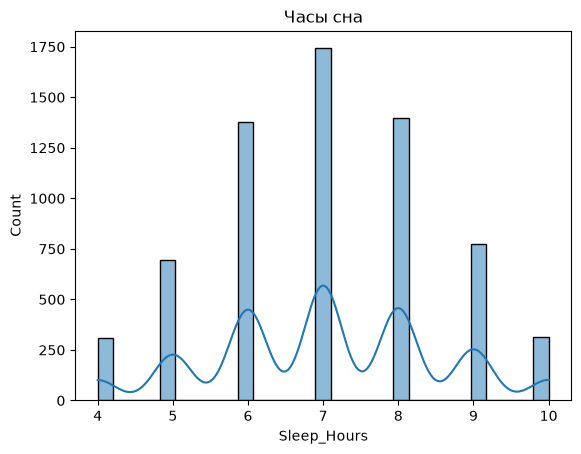

NormaltestResult(statistic=np.float64(129.32306755775704), pvalue=np.float64(8.276613754907294e-29))


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.histplot(df["Sleep_Hours"], kde=True)
plt.title("Часы сна")
plt.show()
print(stats.normaltest(df["Sleep_Hours"]))

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

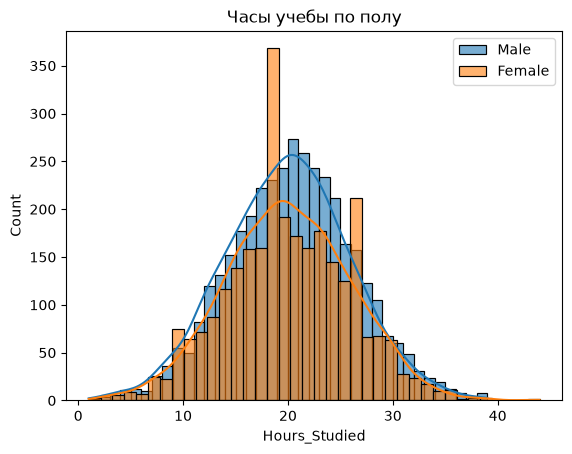

In [25]:
for gender in ["Male", "Female"]:
    sns.histplot(df[df["Gender"] == gender]["Hours_Studied"], alpha=0.6, kde=True, label=gender)
plt.legend()
plt.title("Часы учебы по полу")
plt.show()

3. Как зависит результат конечного экзамена от результата первого экзамена

Корреляция: 0.17507908702291097


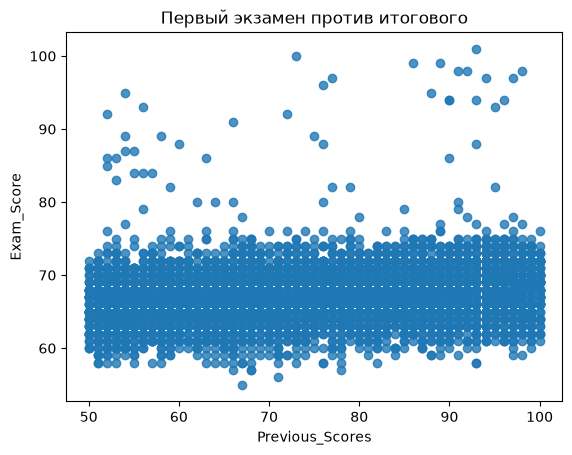

In [26]:
sns.regplot(data=df, x="Previous_Scores", y="Exam_Score")
plt.title("Первый экзамен против итогового")
print("Корреляция:", df["Previous_Scores"].corr(df["Exam_Score"]))
plt.show()

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

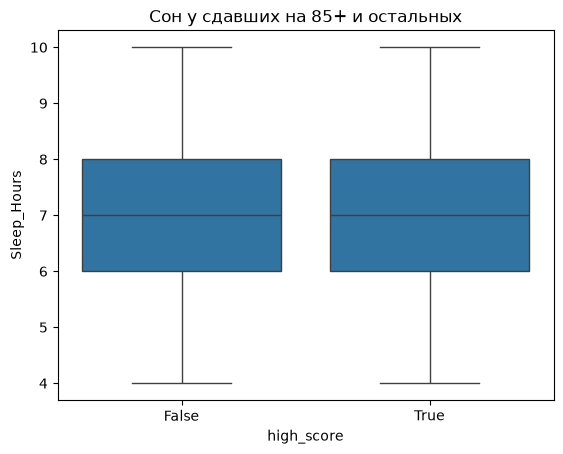

In [27]:
df["high_score"] = df["Exam_Score"] >= 85
sns.boxplot(data=df, x="high_score", y="Sleep_Hours")
plt.title("Сон у сдавших на 85+ и остальных")
plt.show()

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

Корреляция: 0.15652518539225296


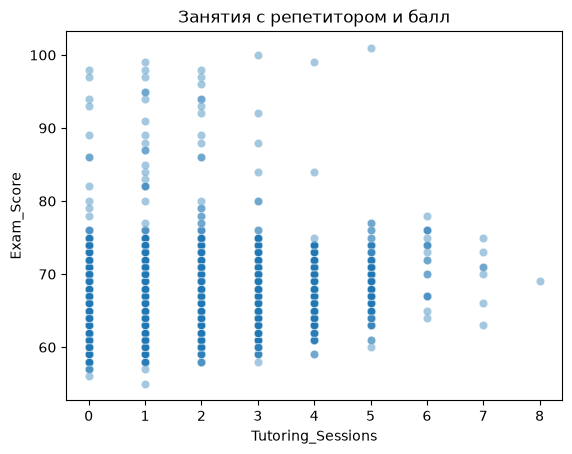

In [28]:
sns.scatterplot(data=df, x="Tutoring_Sessions", y="Exam_Score", alpha=0.4)
plt.title("Занятия с репетитором и балл")
print("Корреляция:", df["Tutoring_Sessions"].corr(df["Exam_Score"]))
plt.show()

6. Как физическая активность влияет на успеваемость?

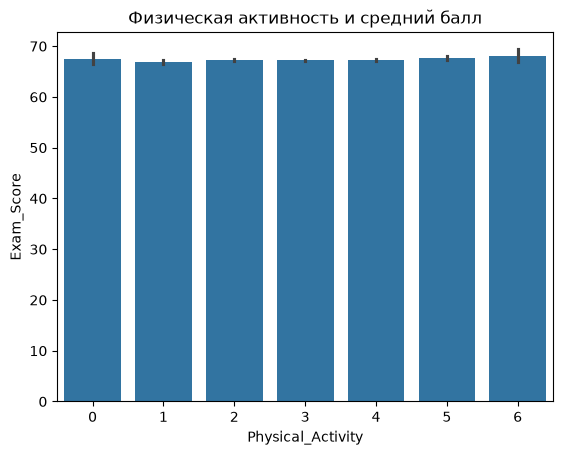

In [29]:
sns.barplot(data=df, x="Physical_Activity", y="Exam_Score")
plt.title("Физическая активность и средний балл")
plt.show()

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

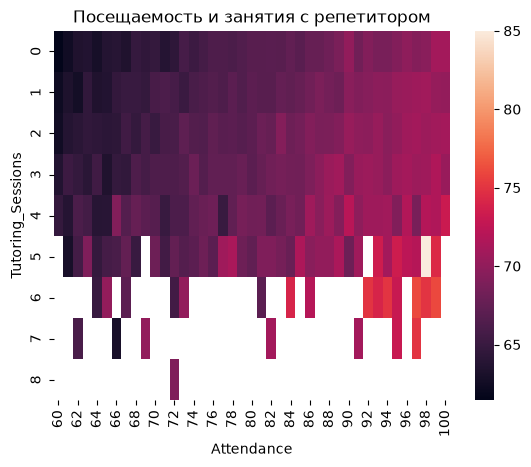

In [30]:
pivot = df.pivot_table(values="Exam_Score", index="Tutoring_Sessions", columns="Attendance", aggfunc="mean")
sns.heatmap(pivot)
plt.title("Посещаемость и занятия с репетитором")
plt.show()